# 04 — Modelling

**Goal:** Build and compare four classifiers for churn prediction.

**Primary metric:** AUC-ROC (ranking quality, robust to class imbalance).
**Also tracked:** precision, recall, F1, confusion matrix.

**Plan:** baseline → Logistic Regression → Random Forest → XGBoost → LightGBM,
all evaluated on the same untouched test set.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay)

import warnings
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)

X_train = pd.read_csv("../data/processed/X_train.csv")
X_test = pd.read_csv("../data/processed/X_test.csv")
X_train_scaled = pd.read_csv("../data/processed/X_train_scaled.csv")
X_test_scaled = pd.read_csv("../data/processed/X_test_scaled.csv")
y_train = pd.read_csv("../data/processed/y_train.csv").squeeze()
y_test = pd.read_csv("../data/processed/y_test.csv").squeeze()

print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (5634, 29) | Test: (1409, 29)


## 1. A reusable evaluation function

All models will be scored by the same function, on the same test set,
so the comparison is fair.

In [2]:
results = []

def evaluate(name, model, X_te, y_te, threshold=0.5):
    proba = model.predict_proba(X_te)[:, 1]
    pred = (proba >= threshold).astype(int)

    results.append({
        "Model": name,
        "AUC": round(roc_auc_score(y_te, proba), 4),
        "Accuracy": round(accuracy_score(y_te, pred), 4),
        "Precision": round(precision_score(y_te, pred, zero_division=0), 4),
        "Recall": round(recall_score(y_te, pred, zero_division=0), 4),
        "F1": round(f1_score(y_te, pred, zero_division=0), 4),
    })
    return proba, pred

## 2. Baseline: a model that learns nothing

Always predicts "stays". Any real model must beat this.

In [3]:
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)

evaluate("Baseline (always 'stays')", dummy, X_test, y_test)
pd.DataFrame(results)

,Model,AUC,Accuracy,Precision,Recall,F1
0,Baseline (always 'stays'),0.5,0.7346,0.0,0.0,0.0


## 3. Logistic Regression

Interpretable baseline. Uses SCALED features. `class_weight="balanced"` makes
errors on churners cost more, countering the 73/27 imbalance.

In [4]:
log_reg = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
log_reg.fit(X_train_scaled, y_train)

proba_lr, pred_lr = evaluate("Logistic Regression", log_reg, X_test_scaled, y_test)
pd.DataFrame(results)

,Model,AUC,Accuracy,Precision,Recall,F1
0,Baseline (always 'stays'),0.5000,0.7346,0.0000,0.0000,0.000
1,Logistic Regression,0.8417,0.7410,0.5078,0.7861,0.617


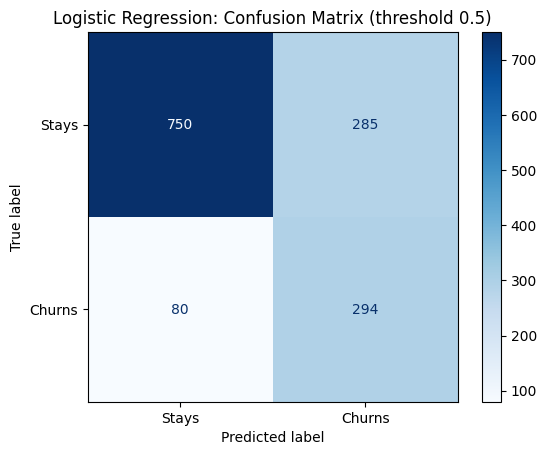

In [5]:
cm = confusion_matrix(y_test, pred_lr)
ConfusionMatrixDisplay(cm, display_labels=["Stays", "Churns"]).plot(cmap="Blues")
plt.title("Logistic Regression: Confusion Matrix (threshold 0.5)")
plt.show()

## 4. Tree-based models

Random Forest (bagging), XGBoost and LightGBM (boosting). Unscaled features.
Hyperparameters are deliberately conservative (shallow trees) to limit overfitting;
tuning comes later.

In [6]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

probas = {"Logistic Regression": proba_lr}

rf = RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=10,
                            class_weight="balanced", random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
probas["Random Forest"], _ = evaluate("Random Forest", rf, X_test, y_test)

neg_pos_ratio = (y_train == 0).sum() / (y_train == 1).sum()
xgb = XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05,
                    subsample=0.8, colsample_bytree=0.8,
                    scale_pos_weight=neg_pos_ratio, eval_metric="logloss",
                    random_state=42)
xgb.fit(X_train, y_train)
probas["XGBoost"], _ = evaluate("XGBoost", xgb, X_test, y_test)

lgbm = LGBMClassifier(n_estimators=300, max_depth=3, num_leaves=8, learning_rate=0.05,
                      colsample_bytree=0.8, class_weight="balanced",
                      random_state=42, verbose=-1)
lgbm.fit(X_train, y_train)
probas["LightGBM"], _ = evaluate("LightGBM", lgbm, X_test, y_test)

print("Class ratio (stay:churn) used for XGBoost:", round(neg_pos_ratio, 2))
pd.DataFrame(results)

Class ratio (stay:churn) used for XGBoost: 2.77


,Model,AUC,Accuracy,Precision,Recall,F1
0,Baseline (always 'stays'),0.5000,0.7346,0.0000,0.0000,0.0000
1,Logistic Regression,0.8417,0.7410,0.5078,0.7861,0.6170
2,Random Forest,0.8439,0.7686,0.5448,0.7807,0.6418
3,XGBoost,0.8427,0.7544,0.5245,0.8021,0.6342
4,LightGBM,0.8412,0.7473,0.5156,0.7968,0.6261


## 5. Comparing all models: ROC curves

The ROC curve plots, for every possible threshold, the share of churners caught
(true positive rate) against the share of loyal customers wrongly flagged
(false positive rate). Curves closer to the top-left corner are better;
the diagonal is a coin flip. AUC is the area under each curve.

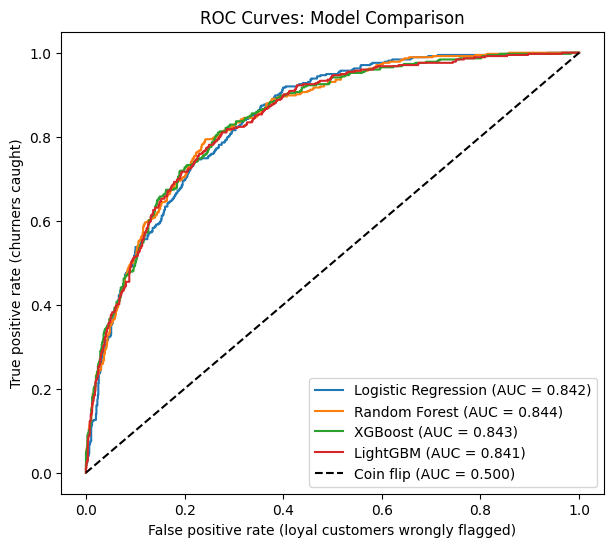

In [7]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(7, 6))
for name, proba in probas.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Coin flip (AUC = 0.500)")
plt.xlabel("False positive rate (loyal customers wrongly flagged)")
plt.ylabel("True positive rate (churners caught)")
plt.title("ROC Curves: Model Comparison")
plt.legend(loc="lower right")
plt.show()